In [1]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.11/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.11/site-packages', '/home/bergerot/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python311.zip', '/usr/lib/python3.11', '/usr/lib/python3.11/lib-dynload', '', '/usr/local/lib/python3.11/dist-packages', '/usr/lib/python3/dist-packages', '/usr/lib/python3.11/dist-packages']


In [2]:
import numpy as np
from scipy.stats import norm

import jax.numpy as jnp
from jax import jit
from functools import partial

from pyCRLD.Agents.Base import abase
from pyCRLD.Utils.Helpers import *

In [3]:
from pyCRLD.Agents.StrategyActorCritic import stratAC
from pyCRLD.Environments.EcologicalPublicGood import EcologicalPublicGood
from pyCRLD.Utils import FlowPlot as fp

import numpy as np
import itertools as it
import matplotlib.pyplot as plt
from pyCRLD.Utils.Helpers import compute_stationarydistribution

from datetime import datetime

/home/bergerot/Documents/PhD/Code/DistRLdynamics/../CRLDenv/lib/python3.11/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [4]:
from DistBase import distbase
from qDDRLBase import qbase

In [32]:
# Define environment
env = EcologicalPublicGood(N=2, f=1.2, c=5, m=-4, qc=0.2, qr=0.1, degraded_choice=True)
env

EcologicalPublicGood_2_1.2_5_-4_0.2_0.1_DegChoi

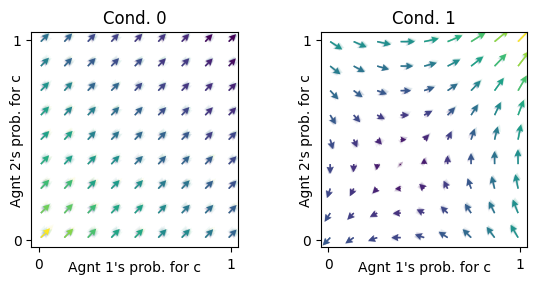

In [33]:
# Init enviornment and MultiAgentEnvironment-interface
mae = stratAC(env=env, learning_rates=0.1, discount_factors=0.9, use_prefactor=True)

x = ([0], [0,1], [0])  # Plotting only the prosperous state
y = ([1], [0,1], [0])  # Plotting only the prosperous state
ax = fp.plot_strategy_flow(mae, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16)

In [34]:
db = distbase(env, nr_reward_bins=29, discretization_sigma=0.1, learning_rates=0.1, discount_factors=0.9)

In [35]:
qb_neutral = qbase(env, nr_reward_bins=29, discretization_sigma=0.1, 
                   learning_rates=0.1, discount_factors=0.9, quantile=0.5)  # sanity check

array([<Axes: title={'center': 'Cond. 0'}, xlabel="Agnt 1's prob. for c", ylabel="Agnt 2's prob. for c">,
       <Axes: title={'center': 'Cond. 1'}, xlabel="Agnt 1's prob. for c", ylabel="Agnt 2's prob. for c">],
      dtype=object)

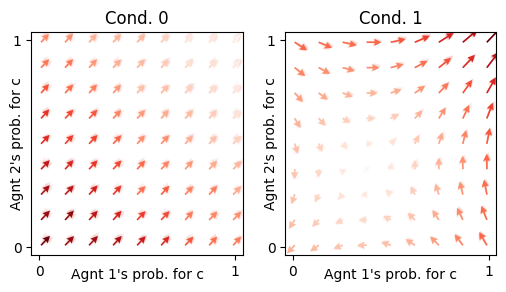

In [53]:
fig, ax = plt.subplots(1, 2, figsize=(6, 2.9))
x = ([0], [0,1], [0])  # Plotting only the prosperous state
y = ([1], [0,1], [0])  # Plotting only the prosperous state
fp.plot_strategy_flow(mae, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16, cmap="Reds", axes=ax)
#fp.plot_strategy_flow(qb_neutral, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16, cmap="Blues", axes=ax)

In [37]:
qb_opt = qbase(env, nr_reward_bins=29, discretization_sigma=0.1, 
                   learning_rates=0.1, discount_factors=0.9, quantile=0.75)  # optimism

array([<Axes: title={'center': 'Cond. 0'}, xlabel="Agnt 1's prob. for c", ylabel="Agnt 2's prob. for c">,
       <Axes: title={'center': 'Cond. 1'}, xlabel="Agnt 1's prob. for c", ylabel="Agnt 2's prob. for c">],
      dtype=object)

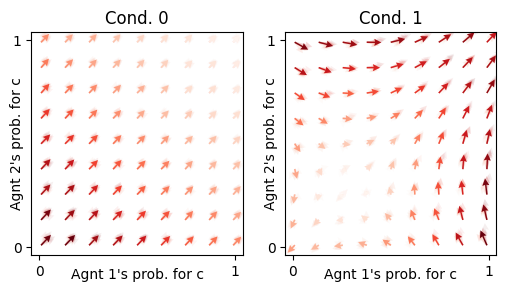

In [52]:
fig, ax = plt.subplots(1, 2, figsize=(6, 2.9))
x = ([0], [0,1], [0])  # Plotting only the prosperous state
y = ([1], [0,1], [0])  # Plotting only the prosperous state
fp.plot_strategy_flow(qb_opt, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16, cmap="Reds", axes=ax)
# fp.plot_strategy_flow(qb_neutral, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16, cmap="Blues", axes=ax)

In [39]:
qb_pes = qbase(env, nr_reward_bins=29, discretization_sigma=0.1, 
                   learning_rates=0.1, discount_factors=0.9, quantile=0.25)  # pessimism

array([<Axes: title={'center': 'Cond. 0'}, xlabel="Agnt 1's prob. for c", ylabel="Agnt 2's prob. for c">,
       <Axes: title={'center': 'Cond. 1'}, xlabel="Agnt 1's prob. for c", ylabel="Agnt 2's prob. for c">],
      dtype=object)

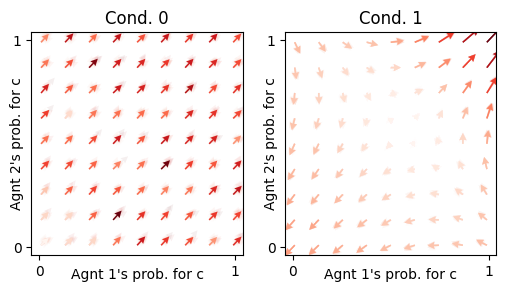

In [54]:
fig, ax = plt.subplots(1, 2, figsize=(6, 2.9))
x = ([0], [0,1], [0])  # Plotting only the prosperous state
y = ([1], [0,1], [0])  # Plotting only the prosperous state
fp.plot_strategy_flow(qb_pes, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16, cmap="Reds", axes=ax)
#fp.plot_strategy_flow(qb_neutral, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16, cmap="Blues", axes=ax)